<a href="https://colab.research.google.com/github/Azidian/Inteligencia_Artificial/blob/main/Componente_practico/Lecture_06/Challenge/01_data_challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [45]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [46]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [47]:
DATA_PATH = PROJECT_DIR / "data" / "wine.csv"

# Asignar los nombres según el diccionario del dataset de vinos
nombres_columnas = [
    "target", "alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium",
    "total_phenols", "flavanoids", "nonflavanoid_phenols", "proanthocyanins",
    "color_intensity", "hue", "od280/od315_of_diluted_wines", "proline"
]

# Leer el CSV indicando que no hay header y pasando los nombres
df = pd.read_csv(DATA_PATH, header=None, names=nombres_columnas)

df.head()

,target,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
1,14.23,1.71,2.43,15.6,127.0,2.8,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
2,13.2,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.4,1050.0,0
3,13.16,2.36,2.67,18.6,101.0,2.8,3.24,0.3,2.81,5.68,1.03,3.17,1185.0,0
4,14.37,1.95,2.5,16.8,113.0,3.85,3.49,0.24,2.18,7.8,0.86,3.45,1480.0,0


In [48]:
print(df.columns)

Index(['target', 'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash',
       'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline'],
      dtype='object')


In [49]:
print("Forma del dataset:", df.shape)

print("\nTipos de datos:")
display(df.dtypes.to_frame(name="dtype"))

print("\nValores nulos por columna:")
display(df.isna().sum().to_frame(name="nulos"))

print("\nFilas duplicadas:", df.duplicated().sum())

print("\nDistribución de target:")
display(df["target"].value_counts().sort_index().to_frame(name="cantidad"))
print("\nDistribución porcentual:")
display((df["target"].value_counts(normalize=True).sort_index() * 100).round(2).to_frame(name="porcentaje"))

Forma del dataset: (179, 14)

Tipos de datos:


,dtype
target,object
alcohol,object
malic_acid,object
ash,object
alcalinity_of_ash,object
magnesium,object
total_phenols,object
flavanoids,object
nonflavanoid_phenols,object
proanthocyanins,object



Valores nulos por columna:


,nulos
target,0
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0



Filas duplicadas: 0

Distribución de target:


,cantidad
target,
11.03,1
11.41,1
11.45,1
11.46,1
11.56,1
...,...
14.38,2
14.39,1
14.75,1



Distribución porcentual:


,porcentaje
target,
11.03,0.56
11.41,0.56
11.45,0.56
11.46,0.56
11.56,0.56
...,...
14.38,1.12
14.39,0.56
14.75,0.56


**Conclusión de calidad:**

Es un dataset limpio sin valores nulos o filas duplicadas, contiene 178 registros y 14 columnas. La variable objetivo tiene tres clases que se encuentran muy bien repartidas con 59, 71 y 48 registros.

La proporción presentada elimina la posibilidad de un problema de desbalance.

## 2. Split train/test

In [50]:
DATA_PATH = PROJECT_DIR / "data" / "wine.csv"

# Leer el CSV normalmente. Pandas detectará la fila de encabezados automáticamente.
df = pd.read_csv(DATA_PATH)

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [51]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [52]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

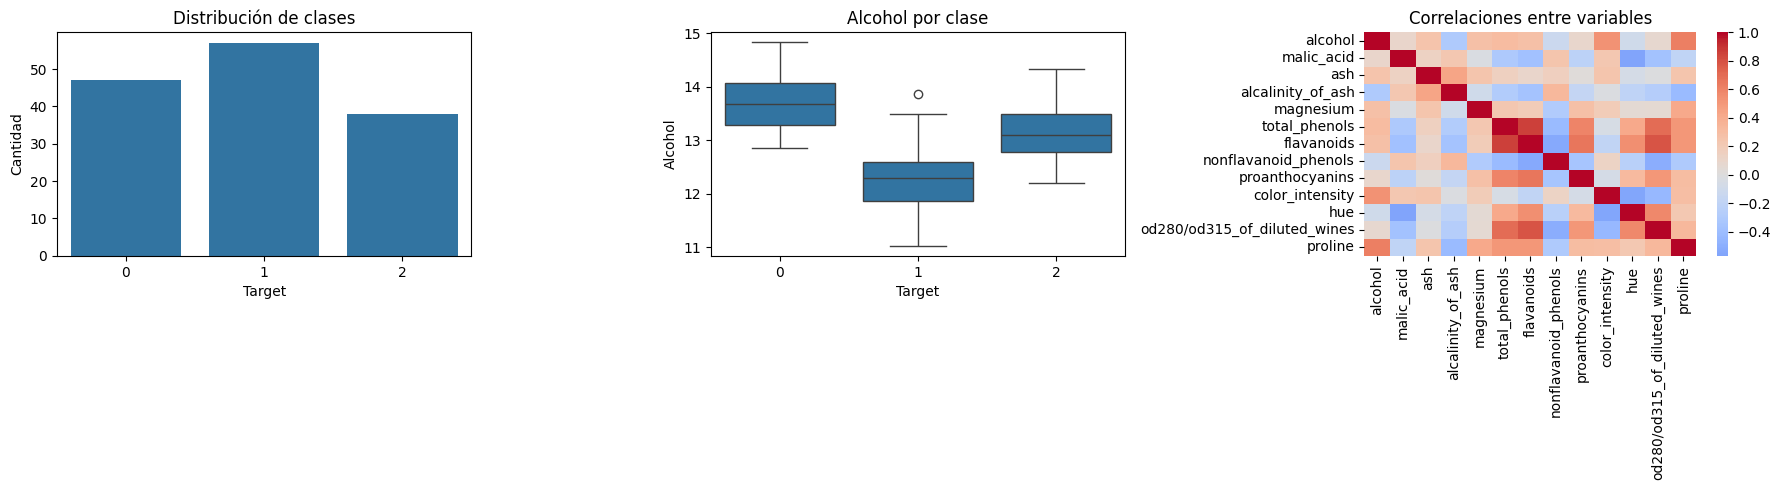

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=train_df, x="target", ax=axes[0])
axes[0].set_title("Distribución de clases")
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Cantidad")

sns.boxplot(data=train_df, x="target", y="alcohol", ax=axes[1])
axes[1].set_title("Alcohol por clase")
axes[1].set_xlabel("Target")
axes[1].set_ylabel("Alcohol")

correlations = train_df.drop(columns="target").corr()
sns.heatmap(correlations, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Correlaciones entre variables")

plt.tight_layout()
plt.show()

**Hallazgos:**

1. La proporción de las clases se encuentra equilibrada, sin embargo, se observa que la clase 1 cuenta con la mayor cantidad de registros, mientras que la clase 2 es la menos representada en el conjunto de datos.
2. La variable correspondiente al alcohol muestra valores centrales, o sea, medianas y dispersiones distintas para cada categoría. Esto sugiere que será un atributo valioso para ayudar al modelo a distinguir correctamente entre las clases.
3. Se identifican variables con correlaciones fuertes entre sí, destacando total_phenols, flavanoids y od280. Además, dado que los atributos manejan magnitudes diferentes, será necesario aplicar un proceso de escalado y tener en cuenta el posible impacto de la multicolinealidad en el modelado.

## 4. Persistencia de datos y contrato

In [54]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

features = [column for column in train_df.columns if column != "target"]
data_contract = {
    "target": "target",
    "features": features,
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}

with open(ARTIFACTS_DIR / "data_contract.json", "w", encoding="utf-8") as file:
    json.dump(data_contract, file, indent=2)

In [55]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/wine.csv`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.